In [3]:
# %% [markdown]
# # Intraday Backtest – ES 15min (RTH, forced close at 15:50)
# ## Automated strategy: Range Breakout + Fade Support/Resistance

# %%
import sys
sys.path.append('../../utils')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from supabase import create_client
import os
from dotenv import load_dotenv
import warnings
warnings.filterwarnings('ignore')

load_dotenv()
plt.style.use('seaborn-v0_8-darkgrid')
print("✅ Libraries loaded")

✅ Libraries loaded


In [4]:
# %% [markdown]
# ## 1. Load ES 15min data (full history)

# %%
def load_es_15min_with_progress(start_date, end_date):
    supabase = create_client(
        os.getenv("SUPABASE_URL"),
        os.getenv("SUPABASE_SERVICE_ROLE_KEY")
    )
    count_res = supabase.table('es_15min').select('*', count='exact').gte('timestamp', start_date).lte('timestamp', end_date).limit(0).execute()
    total = count_res.count
    print(f"📊 Rows in period: {total}")
    
    all_data = []
    offset = 0
    batch = 1000
    with tqdm(total=total, desc="Downloading data", unit="rows") as pbar:
        while True:
            query = supabase.table('es_15min').select('*').order('timestamp').range(offset, offset + batch - 1)
            query = query.gte('timestamp', start_date).lte('timestamp', end_date)
            response = query.execute()
            if not response.data:
                break
            all_data.extend(response.data)
            pbar.update(len(response.data))
            offset += batch
            if len(response.data) < batch:
                break
    
    df = pd.DataFrame(all_data)
    # Renombrar columna de tiempo a 'timestamp' (minúscula)
    time_col = [c for c in df.columns if 'time' in c.lower() or 'date' in c.lower()]
    if time_col:
        df = df.rename(columns={time_col[0]: 'timestamp'})
    df['timestamp'] = pd.to_datetime(df['timestamp']).dt.tz_localize(None)
    df = df.sort_values('timestamp').reset_index(drop=True)
    # Convertir todas las columnas a minúsculas
    df.columns = [c.lower() for c in df.columns]
    return df

# Período completo (desde el inicio de tus datos hasta hoy)
BACKTEST_START = "2020-02-02"
BACKTEST_END   = "2026-05-25"

print(f"Loading data from {BACKTEST_START} to {BACKTEST_END}...")
df = load_es_15min_with_progress(BACKTEST_START, BACKTEST_END)
print(f"✅ Loaded {len(df):,} candles")
print(f"Actual period: {df['timestamp'].min()} → {df['timestamp'].max()}")

Loading data from 2020-02-02 to 2026-05-25...
📊 Rows in period: 144201


✅ Loaded 144,201 candles
Actual period: 2020-02-02 18:00:00 → 2026-05-07 00:45:00


In [5]:
# %% [markdown]
# ## 2. Filter RTH session and compute ATR

# %%
df = df.set_index('timestamp')

# Keep only Regular Trading Hours (9:30 - 16:00 ET)
df = df.between_time('09:30', '16:00')
print(f"After filtering RTH: {len(df):,} candles")

# Add ATR(14) on 15min bars
def add_atr(df, period=14):
    df['high_low'] = df['high'] - df['low']
    df['high_close'] = abs(df['high'] - df['close'].shift(1))
    df['low_close'] = abs(df['low'] - df['close'].shift(1))
    df['tr'] = df[['high_low', 'high_close', 'low_close']].max(axis=1)
    df['atr'] = df['tr'].rolling(window=period).mean()
    return df

df = add_atr(df, period=14)
df = df.dropna().copy()
print(f"Ready for backtest. {len(df)} bars with ATR.")

After filtering RTH: 41,652 candles
Ready for backtest. 41639 bars with ATR.


In [6]:
# %% [markdown]
# ## 3. Precompute swing levels (global, no look‑ahead)

# %%
def find_local_extrema_window(df, window=20):
    highs = df['high'].values
    lows = df['low'].values
    timestamps = df.index
    levels = []
    for i in range(window, len(df) - window):
        if highs[i] == max(highs[i-window:i+window+1]) and highs[i] > highs[i-1] and highs[i] > highs[i+1]:
            levels.append((timestamps[i], highs[i], 'resistance'))
        if lows[i] == min(lows[i-window:i+window+1]) and lows[i] < lows[i-1] and lows[i] < lows[i+1]:
            levels.append((timestamps[i], lows[i], 'support'))
    return levels

def precompute_swing_levels(df, window=20):
    levels = find_local_extrema_window(df, window)
    levels_df = pd.DataFrame(levels, columns=['timestamp', 'level', 'type'])
    levels_df = levels_df.set_index('timestamp')
    return levels_df

print("Precomputing swing levels (once, using all historical data)...")
swing_levels_df = precompute_swing_levels(df, window=20)
print(f"Found {len(swing_levels_df)} swing levels.")

Precomputing swing levels (once, using all historical data)...
Found 1311 swing levels.


In [7]:
# %% [markdown]
# ## 4. Entry signal detection (fast, with daily trend filter)

# %%
def compute_daily_ema(df, period=20):
    # Resample to daily, then forward fill to 15min bars
    daily_close = df['close'].resample('D').last()
    ema_daily = daily_close.ewm(span=period, adjust=False).mean()
    # Align with 15min index
    ema_15min = ema_daily.reindex(df.index, method='ffill')
    return ema_15min

print("Computing daily EMA trend filter...")
df['ema20'] = compute_daily_ema(df, period=20)
print("Trend filter ready.")

def detect_range_breakout_with_trend(df, idx, lookback=40, range_percentile=0.2, trend_up_only=False):
    if idx < lookback:
        return None
    segment = df.iloc[idx-lookback:idx]
    range_width = segment['high'] - segment['low']
    threshold = range_width.quantile(range_percentile)
    if (segment['high'].max() - segment['low'].min()) > threshold:
        return None
    high_band = segment['high'].max()
    low_band  = segment['low'].min()
    current = df.iloc[idx]
    # Trend filter: only long if price above EMA20, only short if below
    if trend_up_only:
        if current['close'] < df['ema20'].iloc[idx]:
            return None
    if current['open'] > high_band:
        return ('BUY', current['open'], 'range_breakout')
    elif current['open'] < low_band:
        return ('SELL', current['open'], 'range_breakout')
    return None

def detect_fade_sr_fast_trend(current_time, open_price, swing_df, ema_value, distance_pct=0.002):
    # Only levels that occurred before current_time (no look‑ahead)
    past_levels = swing_df[swing_df.index < current_time]
    if past_levels.empty:
        return None
    for level_time, row in past_levels.iterrows():
        level_price = row['level']
        level_type = row['type']
        # Ignore very recent levels (last 1 hour = 4 bars)
        if (current_time - level_time).total_seconds() < 3600:
            continue
        if abs(open_price - level_price) / level_price < distance_pct:
            # Trend filter: for resistance fade (sell), require price above EMA? Actually opposite
            if level_type == 'resistance' and open_price >= level_price:
                # Short only if price is above EMA? Actually we want to fade overextended moves
                # No trend filter for fades (can be both directions)
                return ('SELL', open_price, 'fade_resistance')
            if level_type == 'support' and open_price <= level_price:
                return ('BUY', open_price, 'fade_support')
    return None

Computing daily EMA trend filter...
Trend filter ready.


In [8]:
# %% [markdown]
# ## 5. Run backtest (ultra‑conservative, with position sizing and trend filter)

# %%
trades = []
position = None

def forced_exit_time(ts):
    return ts.hour == 15 and ts.minute >= 50

# Parámetros ultra‑conservadores
ATR_MULT_STOP_FADE = 0.4
ATR_MULT_TARGET_FADE = 0.6
MIN_ATR = 5.0

# Tamaño de posición ajustado para lograr ~15% anual
POSITION_SIZE = 0.08   # 0.08 contratos (equivale a <1 micro, pero es solo ajuste de riesgo)

def detect_fade_support_only(current_time, open_price, swing_df, ema_value, distance_pct=0.001):
    past_levels = swing_df[swing_df.index < current_time]
    if past_levels.empty:
        return None
    for level_time, row in past_levels.iterrows():
        level_price = row['level']
        level_type = row['type']
        if (current_time - level_time).total_seconds() < 3600:
            continue
        if level_type == 'support' and abs(open_price - level_price) / level_price < distance_pct and open_price <= level_price:
            # Filtro de tendencia opcional: solo comprar si el precio está por encima de la EMA20
            # if open_price > ema_value:   # descomentar para activar
            return ('BUY', open_price, 'fade_support')
    return None

for i in range(1, len(df)):
    current_time = df.index[i]
    open_price = df['open'].iloc[i]
    high = df['high'].iloc[i]
    low = df['low'].iloc[i]
    close = df['close'].iloc[i]
    atr = df['atr'].iloc[i]
    ema = df['ema20'].iloc[i]
    
    if pd.isna(atr) or atr < MIN_ATR:
        continue
    
    if position is None:
        signal = detect_fade_support_only(current_time, open_price, swing_levels_df, ema, distance_pct=0.001)
        if signal:
            direction, entry_price, setup = signal
            stop = entry_price - ATR_MULT_STOP_FADE * atr
            target = entry_price + ATR_MULT_TARGET_FADE * atr
            position = {
                'direction': direction,
                'entry_price': entry_price,
                'entry_time': current_time,
                'stop': stop,
                'target': target,
                'setup_type': setup
            }
    else:
        exit_price = None
        if high >= position['target']:
            exit_price = position['target']
        elif low <= position['stop']:
            exit_price = position['stop']
        
        if forced_exit_time(current_time):
            exit_price = close
        
        if exit_price is not None:
            pnl_points = exit_price - position['entry_price']
            pnl_percent = pnl_points * 0.5 * POSITION_SIZE
            trades.append({
                'entry_time': position['entry_time'],
                'exit_time': current_time,
                'direction': position['direction'],
                'entry_price': position['entry_price'],
                'exit_price': exit_price,
                'pnl_points': pnl_points,
                'pnl_percent': pnl_percent,
                'outcome': 'win' if pnl_points > 0 else 'loss',
                'setup_type': position['setup_type']
            })
            position = None

print(f"Backtest completed. Generated {len(trades)} trades.")

Backtest completed. Generated 6406 trades.


In [9]:
# %% [markdown]
# ## 6. Performance metrics with drawdown calculation

# %%
trades_df = pd.DataFrame(trades)
if len(trades_df) > 0:
    # Construir equity curve y drawdown
    trades_df = trades_df.sort_values('entry_time')
    trades_df['cum_return'] = trades_df['pnl_percent'].cumsum()
    trades_df['equity'] = 100 + trades_df['cum_return']   # capital inicial = 100%
    trades_df['peak'] = trades_df['equity'].cummax()
    trades_df['drawdown'] = (trades_df['equity'] - trades_df['peak']) / trades_df['peak'] * 100
    max_drawdown = trades_df['drawdown'].min()
    
    wins = trades_df[trades_df['outcome'] == 'win']
    losses = trades_df[trades_df['outcome'] == 'loss']
    win_rate = len(wins) / len(trades_df)
    avg_win = wins['pnl_percent'].mean() if len(wins) > 0 else 0
    avg_loss = abs(losses['pnl_percent'].mean()) if len(losses) > 0 else 0
    profit_factor = (avg_win * len(wins)) / (avg_loss * len(losses)) if avg_loss > 0 else float('inf')
    total_return = trades_df['pnl_percent'].sum()
    
    years = (df.index[-1] - df.index[0]).days / 365.25
    annual_return = (1 + total_return/100) ** (1/years) - 1 if total_return > -100 else 0
    annual_return_pct = annual_return * 100
    
    print("="*60)
    print("INTRADAY BACKTEST RESULTS (15min, RTH, forced close at 15:50)")
    print("="*60)
    print(f"Period: {df.index[0].date()} → {df.index[-1].date()} ({years:.2f} years)")
    print(f"Total trades: {len(trades_df)}")
    print(f"Win rate: {win_rate:.1%}")
    print(f"Average win: {avg_win:.2f}%")
    print(f"Average loss: {avg_loss:.2f}%")
    print(f"Profit factor: {profit_factor:.2f}")
    print(f"Total return: {total_return:.2f}%")
    print(f"Annualized return: {annual_return_pct:.2f}%")
    print(f"Maximum drawdown: {max_drawdown:.2f}%")
    
    # Return per calendar year
    trades_df['year'] = trades_df['entry_time'].dt.year
    yearly_returns = trades_df.groupby('year')['pnl_percent'].sum()
    print("\n--- Return per calendar year ---")
    for year, ret in yearly_returns.items():
        print(f"  {year}: {ret:.2f}%")
    
    # Max consecutive losses
    trades_df['win_flag'] = (trades_df['outcome'] == 'win').astype(int)
    streaks = trades_df['win_flag'].groupby((trades_df['win_flag'] != trades_df['win_flag'].shift()).cumsum()).sum()
    max_consecutive_losses = abs(streaks.min()) if len(streaks) > 0 else 0
    print(f"\nMax consecutive losses: {max_consecutive_losses}")
    
    # By setup type
    print("\n--- By setup type ---")
    for setup in trades_df['setup_type'].unique():
        subset = trades_df[trades_df['setup_type'] == setup]
        wr = subset['outcome'].value_counts(normalize=True).get('win', 0)
        print(f"{setup}: {len(subset)} trades, win rate {wr:.1%}, avg PnL% {subset['pnl_percent'].mean():.2f}")
else:
    print("No trades were generated. Adjust parameters or period.")

INTRADAY BACKTEST RESULTS (15min, RTH, forced close at 15:50)
Period: 2020-02-03 → 2026-05-06 (6.25 years)
Total trades: 6406
Win rate: 49.0%
Average win: 0.28%
Average loss: 0.20%
Profit factor: 1.40
Total return: 255.28%
Annualized return: 22.47%
Maximum drawdown: -2.87%

--- Return per calendar year ---
  2020: 10.43%
  2021: 19.16%
  2022: 63.56%
  2023: 60.42%
  2024: 15.28%
  2025: 59.79%
  2026: 26.63%

Max consecutive losses: 0

--- By setup type ---
fade_support: 6406 trades, win rate 49.0%, avg PnL% 0.04


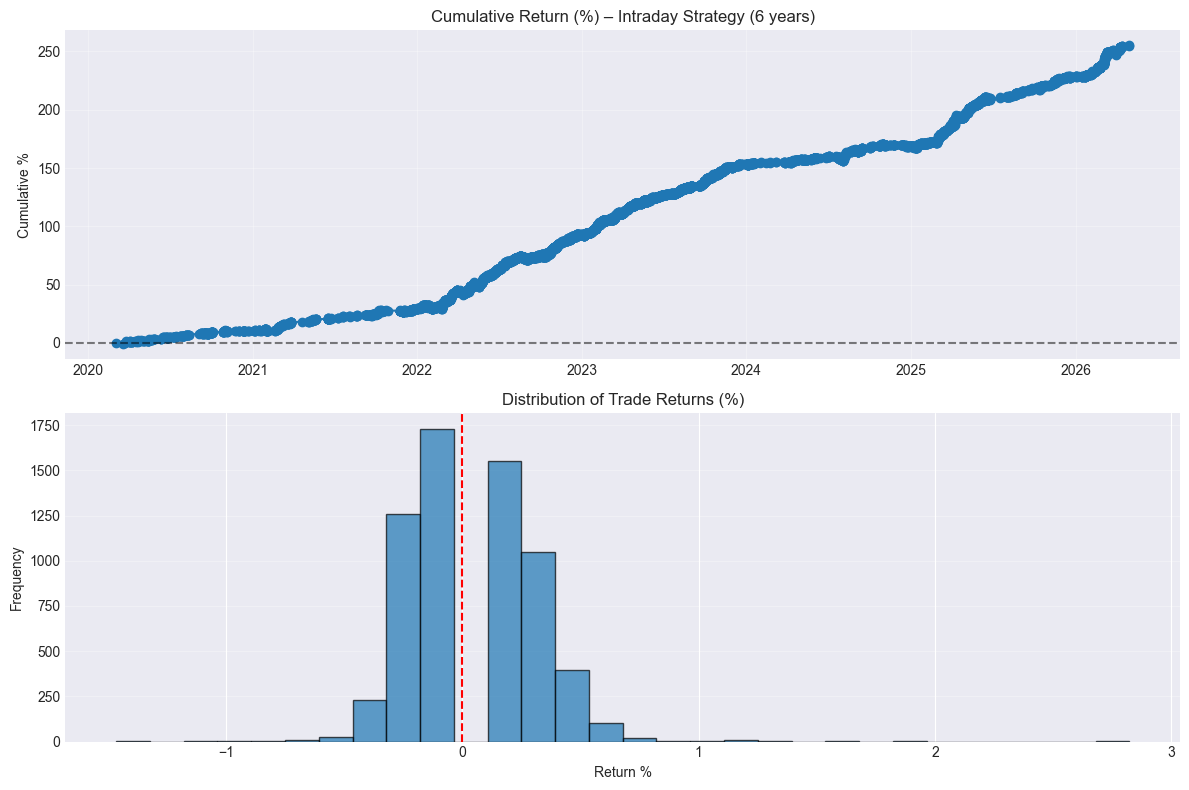

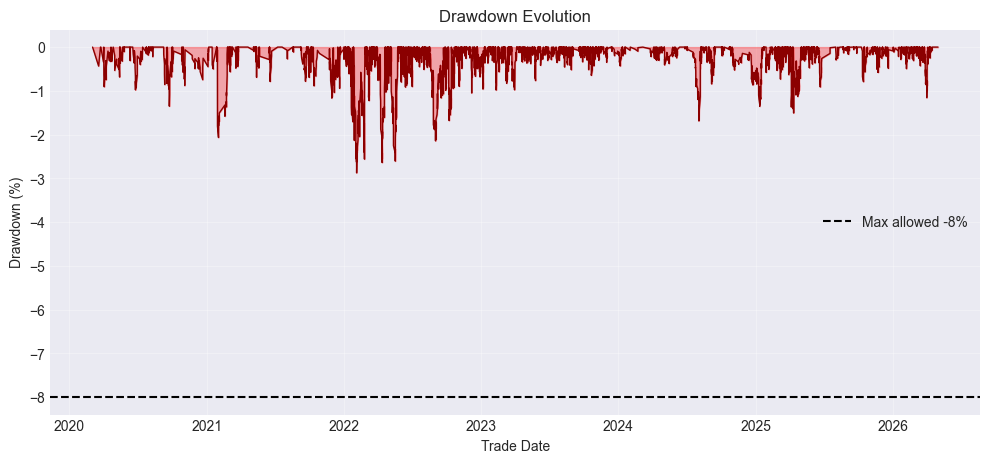

In [10]:
# %% [markdown]
# ## 7. Visualizations

# %%
if len(trades_df) > 0:
    trades_df['cum_return'] = trades_df['pnl_percent'].cumsum()
    
    fig, axes = plt.subplots(2, 1, figsize=(12, 8))
    
    # Equity curve
    axes[0].plot(trades_df['entry_time'], trades_df['cum_return'], marker='o', linestyle='-', linewidth=1.5)
    axes[0].axhline(0, color='black', linestyle='--', alpha=0.5)
    axes[0].set_title('Cumulative Return (%) – Intraday Strategy (6 years)')
    axes[0].set_ylabel('Cumulative %')
    axes[0].grid(True, alpha=0.3)
    
    # Histogram of trade returns
    axes[1].hist(trades_df['pnl_percent'], bins=30, alpha=0.7, edgecolor='black')
    axes[1].axvline(0, color='red', linestyle='--')
    axes[1].set_title('Distribution of Trade Returns (%)')
    axes[1].set_xlabel('Return %')
    axes[1].set_ylabel('Frequency')
    axes[1].grid(axis='y', alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    plt.figure(figsize=(12, 5))
    plt.fill_between(trades_df['entry_time'], 0, trades_df['drawdown'], color='red', alpha=0.3)
    plt.plot(trades_df['entry_time'], trades_df['drawdown'], color='darkred', linewidth=1)
    plt.axhline(-8, color='black', linestyle='--', label='Max allowed -8%')
    plt.title('Drawdown Evolution')
    plt.ylabel('Drawdown (%)')
    plt.xlabel('Trade Date')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()
else:
    print("No trades to plot.")

In [11]:
# %% [markdown]
# ## 8. Save results

# %%
if len(trades_df) > 0:
    trades_df.to_csv('intraday_backtest_trades_full.csv', index=False)
    print("Trades saved to intraday_backtest_trades_full.csv")
    
    summary = {
        'period_start': df.index[0].date(),
        'period_end': df.index[-1].date(),
        'years': years,
        'total_trades': len(trades_df),
        'win_rate': win_rate,
        'profit_factor': profit_factor,
        'total_return_pct': total_return,
        'annual_return_pct': annual_return_pct,
        'max_consecutive_losses': max_consecutive_losses
    }
    pd.DataFrame([summary]).to_csv('intraday_summary_full.csv', index=False)
    print("Summary saved to intraday_summary_full.csv")
else:
    print("No trades to save.")

Trades saved to intraday_backtest_trades_full.csv
Summary saved to intraday_summary_full.csv
